# TPI · Módulo 3 — Extracción de descriptores
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Detección de leucemia linfoblástica aguda (LLA) en imágenes de frotis de sangre periférica*

A partir de la segmentación calculamos números que describen cada célula, para después (Módulo 4) buscar cuáles separan las imágenes benignas de las patológicas. Según el anteproyecto, los linfoblastos tienen **núcleos más grandes, irregulares o hendidos, con alta relación núcleo/citoplasma y cromatina fina**, mientras que los linfocitos maduros y las hematogonias tienen núcleos más chicos, redondos y con cromatina densa.

Contenido:
1. **Diagnóstico de la segmentación de referencia** del dataset (por qué no la usamos).
2. **Intento de segmentar la célula completa** (núcleo + citoplasma) para la relación núcleo/citoplasma: no se pudo validar, y se descarta (ver 2.4).
3. **Descriptores de forma** del núcleo (área, perímetro, circularidad, excentricidad, solidez) y de la imagen (cantidad de núcleos, fracción nuclear).
4. **Descriptores de color** del núcleo (H, S, a\*, b\*) y saturación relativa.
5. **Descriptores de textura** del núcleo: matriz de co-ocurrencia (GLCM) y patrones binarios locales (LBP).
6. **Compresión y descompresión JPEG**: tasa de compresión, calidad de imagen y estabilidad de la segmentación y los descriptores.
7. **Control de integridad** de la tabla final antes de exportarla.

La salida es una tabla con una fila por imagen y una columna por descriptor (`modulo3_descriptores.csv`), que usa el Módulo 4.

## 0. Carga y funciones de los módulos anteriores
Mismo índice del dataset que en los Módulos 1 y 2, la corrección de iluminación por **cierre morfológico** (Módulo 1) y la segmentación del núcleo por ***k*-means global en (a\*, b\*)** (Módulo 2, sección 5). Se copian acá para que el notebook se pueda correr solo.

In [1]:
import os, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from skimage import measure, segmentation
import kagglehub

RUTA = kagglehub.dataset_download('mehradaria/leukemia')
df = pd.DataFrame({'ruta': sorted(glob.glob(f'{RUTA}/**/*.jp*g', recursive=True))})
df['tipo'] = np.where(df.ruta.str.contains('segment', case=False), 'segmentada', 'original')
df['subtipo'] = df.ruta.map(lambda p: os.path.basename(os.path.dirname(p)))
df['clase'] = np.where(df.subtipo.str.contains('benign', case=False), 'no patológica', 'patológica')
df['archivo'] = df.ruta.map(os.path.basename)

org = df[df.tipo == 'original'].reset_index(drop=True)
seg = df[df.tipo == 'segmentada'].set_index(['subtipo', 'archivo']).ruta
org['ruta_seg'] = org.set_index(['subtipo', 'archivo']).index.map(seg.get)
org = org[org.ruta_seg.notna()].reset_index(drop=True)
leer = lambda ruta: cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
subtipos = sorted(org.subtipo.unique())
print(f'Imágenes: {len(org)}')

100%|██████████| 110M/110M [00:01<00:00, 70.1MB/s]

Extracting files...


Imágenes: 3256


In [2]:
# --- Módulo 1: corrección de iluminación (cierre morfológico) ---
TAM_EE = 1 / 3

def estimar_campo(v):
    n = max(v.shape)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(n * TAM_EE) | 1,) * 2)
    return cv2.GaussianBlur(cv2.morphologyEx(v, cv2.MORPH_CLOSE, ee), (0, 0), n / 16)

def preprocesar(rgb):
    h, s, v = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))
    campo = np.maximum(estimar_campo(v.astype(np.float32)), 1)
    v = np.clip(v / campo * campo.mean(), 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2RGB)

# --- Módulo 2: limpieza morfológica y segmentación de referencia (sólo para validar) ---
AREA_MIN_NUC = 100     # px²: debajo es resto/ruido (histograma del área de componentes, commit anterior del Módulo 3)

def limpiar(mask, area_min=25):
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, etq, stats, _ = cv2.connectedComponentsWithStats(m)
    grandes = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etq, grandes)

def sin_marca(mask):
    # Descarta la esquina inferior derecha (marca de agua / barra de escala).
    m = mask.copy(); h, w = m.shape
    m[int(h * 0.88):, int(w * 0.75):] = False
    return m

def mascara_celula(ruta_seg):
    # Segmentación de referencia del dataset (células completas). Sólo se usa para diagnóstico y validación.
    return cv2.cvtColor(leer(ruta_seg), cv2.COLOR_RGB2GRAY) > 10

def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum() + 1e-9)

## 1. Diagnóstico: la segmentación de referencia falla en Pro-B
Cada imagen tiene **varias células**, y la segmentación de referencia del dataset las marca a todas (más algunos restos). Pero en **Pro-B** viene vacía en muchas imágenes aunque se ven células violetas. Medimos, por subtipo, qué fracción de la imagen ocupa la referencia y cuántas imágenes la tienen prácticamente vacía (< 0,5 % de la imagen):

In [3]:
org['roi_frac'] = [mascara_celula(r).mean() for r in org.ruta_seg]
org.groupby('subtipo').roi_frac.agg(
    mediana='median',
    vacias=lambda x: (x < 0.005).sum(),
    pct_vacias=lambda x: 100 * (x < 0.005).mean()).round(3)

,mediana,vacias,pct_vacias
subtipo,,,
Benign,0.079,0,0.000
Early,0.090,0,0.000
Pre,0.214,0,0.000
Pro,0.011,146,18.159


**Resultado** (corrida completa): en Pro-B la referencia ocupa una mediana de **1,1 %** de la imagen (vs. 8–21 % en los demás subtipos) y está vacía en **146 imágenes (18 %)**. Por eso, en el Módulo 2 (sección 5) se reemplazó la segmentación del núcleo por ***k*-means global**, que no usa la referencia y recupera los núcleos de Pro-B (de 30 % a 0 % de imágenes sin núcleo).

Al dejar de usar la referencia perdemos también el contorno de la **célula completa**, necesario para la **relación núcleo/citoplasma**, uno de los criterios morfológicos clásicos del linfoblasto. La sección 2 lo resuelve.

## 2. Segmentación de la célula (núcleo + citoplasma) sin referencia
### 2.1 Método
El *k*-means global del Módulo 2 agrupa los píxeles en 3 clusters por color (a\*, b\*), ordenados por croma:
- **núcleo** (mayor croma: violeta intenso),
- **teñido intermedio**: citoplasma y glóbulos rojos,
- **fondo** (menor croma: plasma casi blanco).

Como el citoplasma es un celeste muy pálido, por croma puede confundirse con el fondo; por eso un píxel se considera **teñido** si no está en el cluster de fondo **o** si es más oscuro que el fondo (umbral de Otsu sobre la luminosidad L\*).

La **célula** de cada núcleo se arma "creciendo" el núcleo sobre los píxeles teñidos (no fondo) que lo rodean:
1. Cada píxel teñido se asigna al **núcleo más cercano** (transformada de distancia). Así, cuando dos células se tocan, el límite queda a mitad de camino entre sus núcleos.
2. Para no incorporar glóbulos rojos vecinos, el crecimiento se limita a un **anillo de ancho proporcional al tamaño del núcleo**: un píxel pertenece a la célula si está a una distancia del borde del núcleo menor que $(F-1)\cdot r_{eq}$, con $r_{eq}=\sqrt{A_{núcleo}/\pi}$. Con $F$ = 1,5 la célula puede tener hasta 1,5 veces el radio del núcleo.
3. Se rellenan huecos y se conserva sólo la parte conectada al núcleo.

La inicialización de *k*-means es aleatoria, así que se fija la semilla (42) para que todo el notebook sea **reproducible**: correrlo de nuevo da exactamente los mismos números.

El parámetro $F$ se elige con un **barrido** (*grid search*) contra la referencia (sección 2.2).

In [4]:
def kmeans_clusters(rgb, k=3):
    # k-means en (a*, b*) sobre todos los píxeles. Devuelve etiquetas ordenadas por croma: 0 = fondo, ..., k-1 = núcleo.
    cv2.setRNGSeed(42)    # semilla fija: la inicialización de k-means es aleatoria; así los resultados son reproducibles
    ab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[..., 1:].reshape(-1, 2) - 128
    _, etq, centros = cv2.kmeans(ab, k, None, (cv2.TERM_CRITERIA_EPS, 20, 0.5), 3, cv2.KMEANS_PP_CENTERS)
    orden = np.argsort(np.argsort(np.linalg.norm(centros, axis=1)))     # rango de croma de cada cluster
    return orden[etq.ravel()].reshape(rgb.shape[:2])

def segmentar_componentes(rgb):
    # Núcleos etiquetados (1..N) y máscara de píxeles teñidos (no fondo).
    cl = kmeans_clusters(rgb)
    nuc = sin_marca(ndi.binary_fill_holes(limpiar(cl == 2, AREA_MIN_NUC)))    # = segmentar_kmeans_global del Módulo 2
    # Teñido = no es fondo por color (cluster >= 1) O es más oscuro que el fondo (Otsu sobre L*):
    # el citoplasma es celeste muy pálido y por croma sólo puede confundirse con el fondo, pero es más oscuro.
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    umbral_L, _ = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tenido = sin_marca(limpiar((cl >= 1) | (L < umbral_L))) | nuc
    return measure.label(nuc), tenido

def crecer_celulas(nucleos, tenido, F):
    # Célula de cada núcleo: píxeles teñidos más cercanos a ese núcleo, dentro de un anillo de ancho (F-1)·r_eq.
    if nucleos.max() == 0:
        return np.zeros_like(nucleos)
    dist, (iy, ix) = ndi.distance_transform_edt(nucleos == 0, return_indices=True)
    mas_cercano = nucleos[iy, ix]
    areas = np.bincount(nucleos.ravel())
    r_eq = np.sqrt(areas / np.pi)
    celulas = np.where(tenido & (dist <= (F - 1) * r_eq[mas_cercano]), mas_cercano, 0)
    celulas[nucleos > 0] = nucleos[nucleos > 0]
    salida = np.zeros_like(celulas)
    for i in range(1, nucleos.max() + 1):                     # sólo la parte conectada al núcleo, sin huecos
        comp = measure.label(celulas == i)
        ids = np.unique(comp[nucleos == i]); ids = ids[ids > 0]
        salida[ndi.binary_fill_holes(np.isin(comp, ids))] = i
    return salida

### 2.2 Validación y elección de F
En **Benign, Early y Pre**, donde la referencia funciona, comparamos nuestras células con las de la referencia. Tomamos los núcleos que caen mayormente (> 50 %) dentro de la referencia y, para esos, medimos:
- **Dice** entre nuestras células y las células de la referencia que contienen esos núcleos;
- la **relación núcleo/célula** de la imagen calculada con nuestras células vs. con las de la referencia (**correlación de Spearman** y error absoluto medio).

**Criterio de aceptación (fijado antes de correr):** Dice medio ≥ 0,70 **y** Spearman ≥ 0,6 para el mejor $F$. Si no se cumple, se descarta la relación núcleo/célula y se usa como alternativa la fracción de la imagen ocupada por núcleos.

Se prueba también $F = 10$ (crecimiento prácticamente sin límite) como referencia de qué pasa si no se limita el anillo.

In [5]:
F_GRILLA = [1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 10]
muestra = org[~org.subtipo.str.contains('Pro')].groupby('subtipo').sample(40, random_state=0)
filas = []
for r in muestra.itertuples():
    rgb, roi = preprocesar(leer(r.ruta)), mascara_celula(r.ruta_seg)
    nucleos, tenido = segmentar_componentes(rgb)
    props = measure.regionprops(nucleos)
    adentro = [p.label for p in props if roi[nucleos == p.label].mean() > 0.5]
    if not adentro:
        continue
    nuc_ok = np.isin(nucleos, adentro)
    roi_lab = measure.label(roi)
    ids_ref = np.unique(roi_lab[nuc_ok]); ids_ref = ids_ref[ids_ref > 0]
    ref = np.isin(roi_lab, ids_ref)
    for F in F_GRILLA:
        cel = np.isin(crecer_celulas(nucleos, tenido, F), adentro)
        filas.append(dict(subtipo=r.subtipo, archivo=r.archivo, F=F, dice=dice(cel, ref),
                          nc_nuestra=nuc_ok.sum() / cel.sum(), nc_ref=(nuc_ok & ref).sum() / ref.sum()))
val = pd.DataFrame(filas)
tabla_F = val.groupby('F').apply(lambda g: pd.Series(dict(
    dice=g.dice.mean(),
    spearman_nc=spearmanr(g.nc_nuestra, g.nc_ref).correlation,
    error_nc=(g.nc_nuestra - g.nc_ref).abs().mean())), include_groups=False)
F_CITO = tabla_F.dice.idxmax()
print(f"Mejor F = {F_CITO}  ->  acepta: {tabla_F.loc[F_CITO, 'dice'] >= 0.70 and tabla_F.loc[F_CITO, 'spearman_nc'] >= 0.6}")
tabla_F.round(3)

Mejor F = 1.2  ->  acepta: False


,dice,spearman_nc,error_nc
F,,,
1.2,0.862,0.143,0.083
1.4,0.824,0.085,0.151
1.6,0.787,-0.032,0.208
1.8,0.753,-0.085,0.257
2.0,0.723,-0.119,0.294
2.5,0.668,-0.151,0.359
10.0,0.566,-0.155,0.458


In [6]:
# Detalle por subtipo con el F elegido
val[val.F == F_CITO].groupby('subtipo')[['dice', 'nc_nuestra', 'nc_ref']].mean().round(3)

,dice,nc_nuestra,nc_ref
subtipo,,,
Benign,0.824,0.749,0.802
Early,0.896,0.783,0.866
Pre,0.866,0.790,0.819


### 2.3 Ejemplos
Una imagen por subtipo (incluida Pro-B, donde no hay referencia para comparar): contorno **verde** = núcleo, **amarillo** = célula (núcleo + citoplasma) con el $F$ elegido, **rojo** punteado = referencia del dataset.

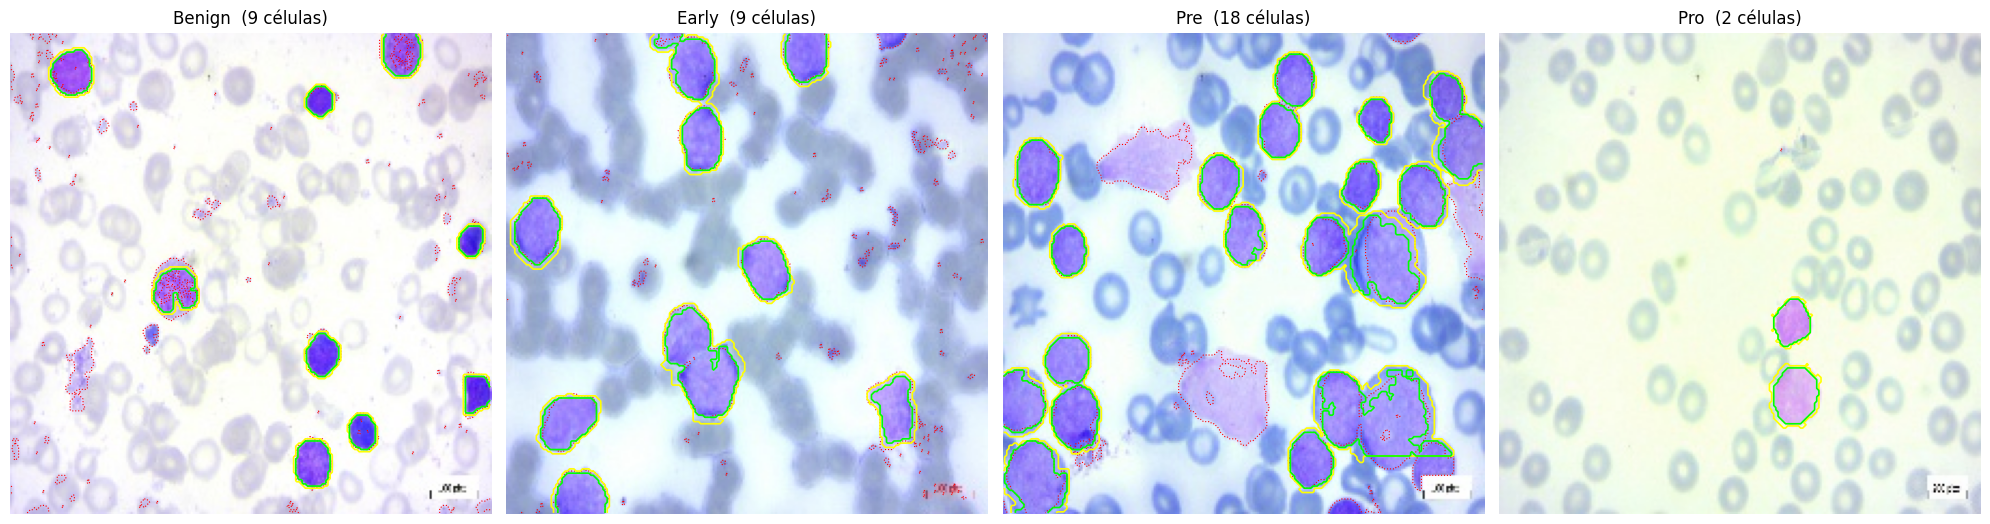

In [7]:
fig, ax = plt.subplots(1, len(subtipos), figsize=(5 * len(subtipos), 5.4))
for a, st in zip(ax, subtipos):
    r = org[org.subtipo == st].sample(1, random_state=1).iloc[0]
    rgb = preprocesar(leer(r.ruta))
    nucleos, tenido = segmentar_componentes(rgb)
    cel = crecer_celulas(nucleos, tenido, F_CITO)
    a.imshow(rgb)
    a.contour(mascara_celula(r.ruta_seg), [0.5], colors='red', linewidths=0.8, linestyles='dotted')
    a.contour(cel > 0, [0.5], colors='yellow', linewidths=1.2)
    a.contour(nucleos > 0, [0.5], colors='lime', linewidths=1.2)
    a.set_title(f'{st}  ({nucleos.max()} células)'); a.axis('off')
plt.tight_layout()

### 2.4 Conclusión de la sección 2: se descarta la relación núcleo/citoplasma
**No se cumple el criterio de aceptación.** El Dice es alto (0,86 con $F$ = 1,2), pero la correlación entre la relación núcleo/célula nuestra y la de la referencia es prácticamente nula (Spearman 0,14 con $F$ = 1,2, y negativa para $F$ ≥ 1,6).

**Por qué:** el mejor Dice se obtiene con el $F$ más chico (casi sin citoplasma) y la relación núcleo/célula de la referencia da 0,80–0,87. Es decir, **la segmentación de referencia del dataset no marca la célula completa, sino prácticamente el núcleo** (en los ejemplos de 2.3 el contorno rojo queda pegado al núcleo). Entonces:
- no hay contra qué validar el citoplasma, y la "relación núcleo/célula de referencia" no es la relación núcleo/citoplasma real;
- además, en estas imágenes el citoplasma de los linfocitos es un anillo muy fino y pálido, difícil de separar por color de los glóbulos rojos adyacentes.

**Nota:** por el mismo motivo, el `rel_nc` de la primera versión de este módulo (núcleo / referencia) tampoco medía la relación núcleo/citoplasma.

**Decisión:** no se usa la relación núcleo/citoplasma. En su lugar se usan descriptores que no dependen del citoplasma: la **fracción de la imagen ocupada por núcleos** (`frac_nuclear`) y la **cantidad de núcleos** (`n_nucleos`). Medir la relación núcleo/citoplasma queda como **mejora futura**: requeriría máscaras de citoplasma validadas manualmente (o imágenes de mayor resolución donde el citoplasma sea distinguible).

## 3. Descriptores de forma
Se miden **núcleo por núcleo** y se resumen por imagen con la **mediana** (no se deja arrastrar por un núcleo mal segmentado). Los núcleos que **tocan el borde** de la imagen están cortados, así que se excluyen del cálculo de forma (si todos tocan el borde, se usan igual). La cantidad de núcleos y la fracción nuclear sí cuentan todos.

| Descriptor | Qué mide | Qué esperamos en LLA |
|---|---|---|
| `area` | tamaño del núcleo [px²] | mayor |
| `perimetro` | largo del contorno del núcleo [px] | mayor |
| `circularidad` | $4\pi A / P^2$: 1 = círculo perfecto, baja si el borde es irregular | menor |
| `excentricidad` | 0 = círculo, →1 = alargado (elipse equivalente) | — |
| `solidez` | área / área de la envolvente convexa: < 1 si hay hendiduras | menor |
| `n_nucleos` | cantidad de núcleos detectados en la imagen | mayor (más blastos) |
| `frac_nuclear` | fracción de la imagen ocupada por núcleos | mayor |

In [8]:
FORMA = ['area', 'perimetro', 'circularidad', 'excentricidad', 'solidez', 'n_nucleos', 'frac_nuclear']

def descriptores_forma(nucleos):
    # Resumen por imagen: mediana por núcleo (sin los que tocan el borde) + n_nucleos + frac_nuclear.
    d = dict(n_nucleos=int(nucleos.max()), frac_nuclear=(nucleos > 0).mean())
    internos = segmentation.clear_border(nucleos)
    usar = internos if internos.max() > 0 else nucleos
    filas = []
    for p in measure.regionprops(usar):
        per = p.perimeter
        filas.append(dict(area=p.area, perimetro=per,
                          circularidad=4 * np.pi * p.area / per**2 if per > 0 else np.nan,
                          excentricidad=p.eccentricity, solidez=p.solidity))
    if not filas:
        return {**{k: np.nan for k in FORMA}, **d}
    return {**pd.DataFrame(filas).median().to_dict(), **d}

### 3.1 Cálculo sobre todo el dataset
Una pasada por las 3.256 imágenes (unos minutos). El resultado queda en la tabla `desc`, que se va completando en las secciones siguientes.

In [9]:
filas = []
for r in org.itertuples():
    rgb = preprocesar(leer(r.ruta))
    nucleos, _ = segmentar_componentes(rgb)
    filas.append(dict(archivo=r.archivo, subtipo=r.subtipo, clase=r.clase, **descriptores_forma(nucleos)))
desc = pd.DataFrame(filas)
print(f"Imágenes sin núcleo detectado: {(desc.n_nucleos == 0).sum()}  (por subtipo: {desc[desc.n_nucleos == 0].subtipo.value_counts().to_dict()})")
desc.groupby('subtipo')[FORMA].median().round(3)

Imágenes sin núcleo detectado: 0  (por subtipo: {})


,area,perimetro,circularidad,excentricidad,solidez,n_nucleos,frac_nuclear
subtipo,,,,,,,
Benign,351.0,76.173,0.819,0.705,0.936,8.0,0.063
Early,483.5,84.426,0.854,0.710,0.953,6.0,0.065
Pre,425.0,80.423,0.863,0.710,0.953,18.0,0.166
Pro,373.0,73.380,0.879,0.719,0.955,6.0,0.042


### 3.2 Comparación entre clases
Boxplots de cada descriptor por subtipo. Buscamos descriptores donde la caja de **Benign** quede separada de las de los subtipos de LLA: son los candidatos para las reglas de clasificación del Módulo 4 (donde se evalúa formalmente con Mann-Whitney y curvas ROC).

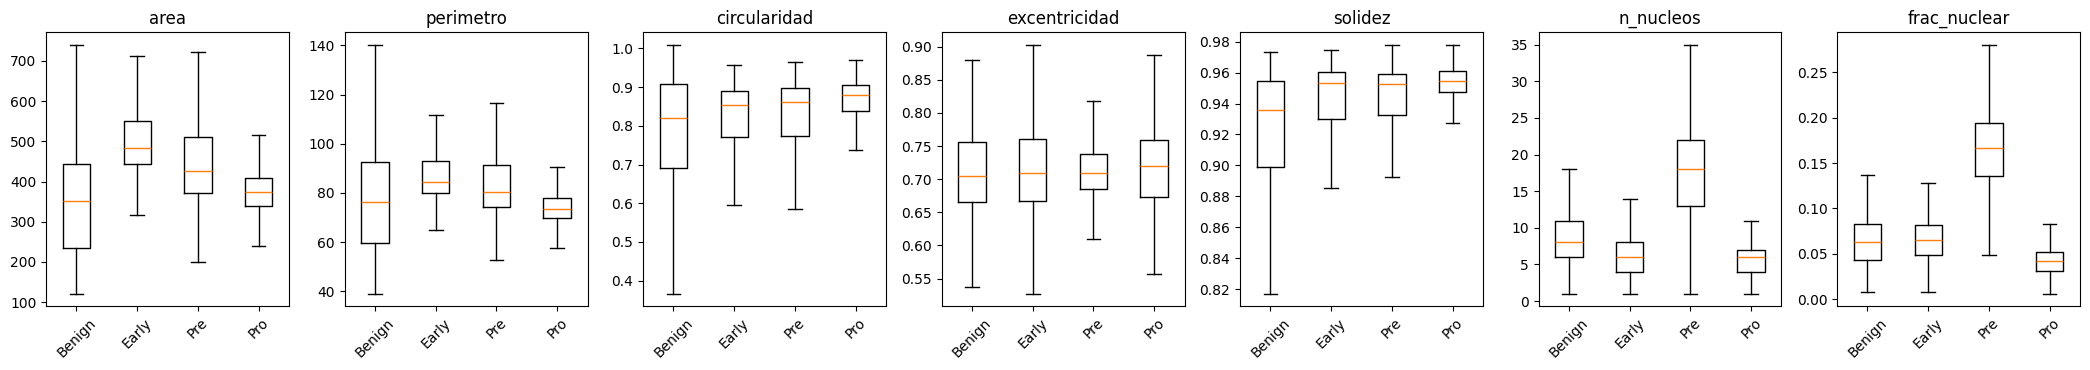

In [10]:
fig, ax = plt.subplots(1, len(FORMA), figsize=(3 * len(FORMA), 3.8))
for a, var in zip(ax, FORMA):
    a.boxplot([desc.loc[desc.subtipo == st, var].dropna() for st in subtipos], showfliers=False)
    a.set_xticks(range(1, len(subtipos) + 1), subtipos, rotation=45)
    a.set_title(var)
plt.tight_layout()

In [11]:
# Mediana por clase binaria del proyecto
desc.groupby('clase')[FORMA].median().round(3).T

clase,no patológica,patológica
area,351.000,432.000
perimetro,76.173,80.209
circularidad,0.819,0.865
excentricidad,0.705,0.712
solidez,0.936,0.954
n_nucleos,8.000,7.000
frac_nuclear,0.063,0.065


### 3.3 Observaciones
- **Área (y perímetro):** los núcleos de las imágenes patológicas son más grandes (mediana ~430 vs. ~350 px²), sobre todo en Early y Pre, como se esperaba para linfoblastos. Es el candidato más claro para el Módulo 4.
- **Circularidad y solidez: al revés de lo esperado.** Las imágenes benignas tienen núcleos *menos* circulares y menos sólidos (circularidad ~0,82 vs. ~0,87). **Hipótesis:** en las imágenes benignas aparecen otros leucocitos además de linfocitos/hematogonias (p. ej. neutrófilos con núcleo lobulado, visible en el ejemplo Benign de 2.3), que bajan la circularidad. A verificar inspeccionando las imágenes benignas con menor circularidad.
- **n_nucleos y frac_nuclear:** muy altos en Pre-B y parecidos entre Benign, Early y Pro-B: separan más un subtipo que la clase binaria.
- **Pro-B** ahora tiene valores comparables a los demás subtipos (núcleos detectados en todas las imágenes), gracias a la segmentación sin referencia del Módulo 2.

## 4. Descriptores de color
Se calculan sobre los **píxeles del núcleo** de cada imagen (todos los núcleos juntos), en los dos espacios de color que se usaron para segmentar:

| Descriptor | Qué mide |
|---|---|
| `H_media`, `H_desvio` | tono del núcleo (violeta/azul) y su variabilidad; **estadística circular**, porque el tono es un ángulo (0 y 180 son el mismo rojo en OpenCV) |
| `S_media`, `S_desvio` | saturación (intensidad de la tinción) y su variabilidad dentro del núcleo |
| `a_media`, `a_desvio`, `b_media`, `b_desvio` | componentes cromáticas de CIE Lab (a\* verde↔magenta, b\* azul↔amarillo) |
| `S_rel` | saturación media del núcleo / saturación media del resto de lo teñido (citoplasma y glóbulos rojos) **de la misma imagen** |

**Cuidado con la tinción:** el color absoluto depende de cómo se tiñó cada muestra (el Módulo 1 mostró que Pro-B está teñido más pálido). Si un descriptor de color separa las clases sólo porque los subtipos se tiñeron distinto, el clasificador aprendería el *lote de tinción* y no la biología. `S_rel` compara el núcleo con el resto de la **misma** imagen, así que es más robusto a que la muestra entera haya quedado más clara u oscura. En el Módulo 4 hay que tenerlo en cuenta al elegir descriptores.

In [12]:
COLOR = ['H_media', 'H_desvio', 'S_media', 'S_desvio', 'a_media', 'a_desvio', 'b_media', 'b_desvio', 'S_rel']

def media_desvio_circular(h):
    # Media y desvío circulares del tono de OpenCV (H en [0, 180) -> ángulo en [0, 2π)).
    ang = h.astype(float) * 2 * np.pi / 180
    c, s = np.cos(ang).mean(), np.sin(ang).mean()
    R = np.hypot(c, s)
    media = (np.arctan2(s, c) % (2 * np.pi)) * 180 / (2 * np.pi)
    desvio = np.sqrt(-2 * np.log(max(R, 1e-12))) * 180 / (2 * np.pi)
    return media, desvio

def descriptores_color(rgb, nucleos, tenido):
    nuc = nucleos > 0
    if not nuc.any():
        return {k: np.nan for k in COLOR}
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(float) - [0, 128, 128]
    h_m, h_d = media_desvio_circular(hsv[..., 0][nuc])
    s, a, b = hsv[..., 1][nuc].astype(float), lab[..., 1][nuc], lab[..., 2][nuc]
    resto = tenido & ~nuc
    s_resto = hsv[..., 1][resto].mean() if resto.any() else np.nan
    return dict(H_media=h_m, H_desvio=h_d, S_media=s.mean(), S_desvio=s.std(),
                a_media=a.mean(), a_desvio=a.std(), b_media=b.mean(), b_desvio=b.std(),
                S_rel=s.mean() / s_resto if s_resto and s_resto > 0 else np.nan)

### 4.1 Cálculo sobre todo el dataset
Otra pasada por todas las imágenes (misma segmentación que la sección 3). Los descriptores se agregan como columnas nuevas a `desc`.

In [13]:
filas = []
for r in org.itertuples():
    rgb = preprocesar(leer(r.ruta))
    nucleos, tenido = segmentar_componentes(rgb)
    filas.append(dict(archivo=r.archivo, subtipo=r.subtipo, **descriptores_color(rgb, nucleos, tenido)))
color = pd.DataFrame(filas)
desc = desc.drop(columns=[c for c in COLOR if c in desc], errors='ignore').merge(color, on=['archivo', 'subtipo'])
desc.groupby('subtipo')[COLOR].median().round(3)

,H_media,H_desvio,S_media,S_desvio,a_media,a_desvio,b_media,b_desvio,S_rel
subtipo,,,,,,,,,
Benign,125.735,3.211,116.519,27.075,31.787,9.687,-52.448,11.713,3.059
Early,125.913,2.207,124.544,18.936,36.828,7.559,-57.231,8.526,2.390
Pre,123.818,2.347,117.771,17.114,32.771,6.970,-54.954,7.907,1.371
Pro,136.406,3.098,76.583,14.297,28.790,5.807,-31.435,6.224,2.285


### 4.2 Comparación entre clases

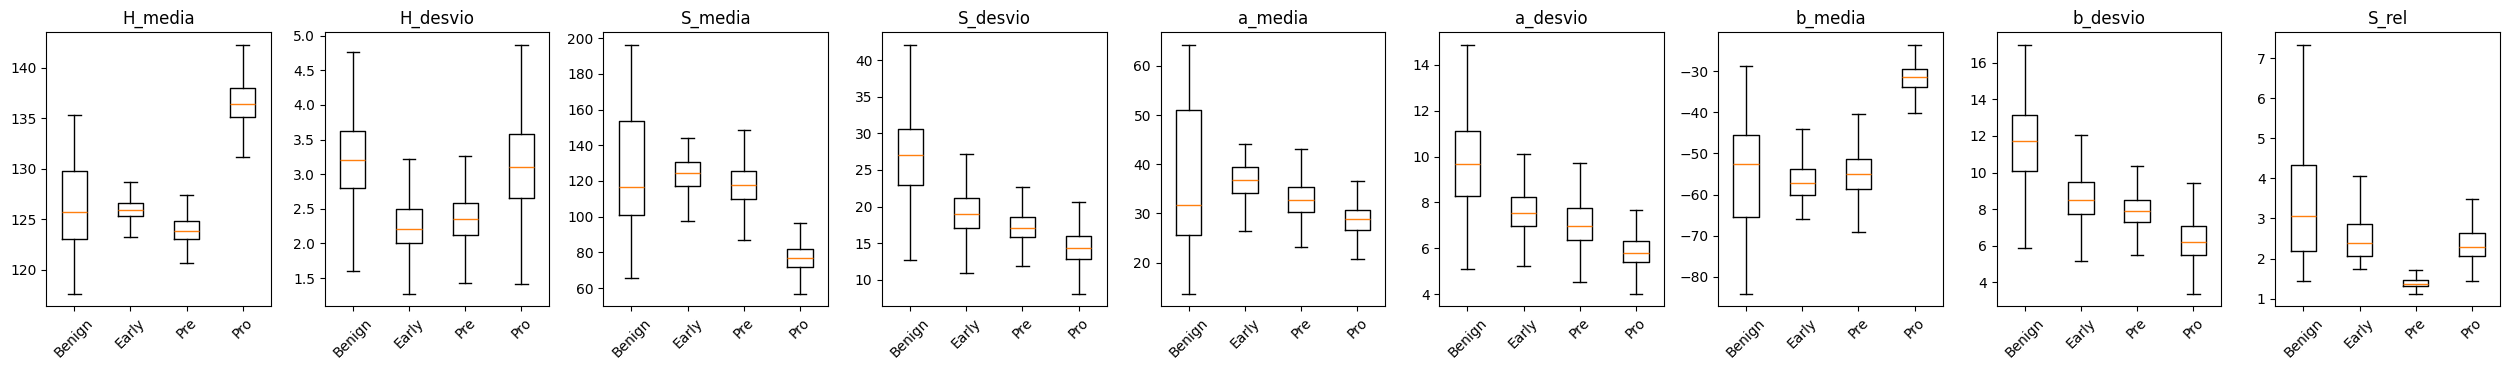

In [14]:
fig, ax = plt.subplots(1, len(COLOR), figsize=(2.8 * len(COLOR), 3.8))
for a, var in zip(ax, COLOR):
    a.boxplot([desc.loc[desc.subtipo == st, var].dropna() for st in subtipos], showfliers=False)
    a.set_xticks(range(1, len(subtipos) + 1), subtipos, rotation=45)
    a.set_title(var)
plt.tight_layout()

In [15]:
desc.groupby('clase')[COLOR].median().round(3).T

clase,no patológica,patológica
H_media,125.735,126.068
H_desvio,3.211,2.422
S_media,116.519,114.910
S_desvio,27.075,17.008
a_media,31.787,32.823
a_desvio,9.687,6.882
b_media,-52.448,-53.115
b_desvio,11.713,7.764
S_rel,3.059,2.049


### 4.3 Observaciones
- **El color absoluto refleja la tinción de cada subtipo, no la clase.** Las medias de H, S, a\* y b\* son casi iguales entre Benign, Early y Pre, mientras que **Pro-B se separa de todos** (S ≈ 77 vs. ≈ 120, b\* ≈ −31 vs. ≈ −55, tono más rosado): es el lote de tinción más pálido ya visto en los Módulos 1 y 2. Por eso las **medias de color no se proponen para el Módulo 4**: separarían Pro-B por un efecto del laboratorio, no de la biología.
- **La variabilidad del color dentro del núcleo sí muestra diferencias entre clases** (su capacidad discriminativa se evalúa en el Módulo 4). Los desvíos son mayores en las benignas (desvío de S ≈ 27 vs. ≈ 17; de b\* ≈ 11,7 vs. ≈ 7,8; de a\* ≈ 9,7 vs. ≈ 6,9). Es coherente con la morfología esperada: los linfocitos maduros tienen **cromatina condensada en grumos** (zonas muy oscuras y otras más claras), mientras que los linfoblastos tienen **cromatina fina y homogénea**. Esto anticipa lo que debería medir el análisis de textura (sección 5). *Cuidado:* parte del menor desvío de Pro-B puede deberse a que toda la imagen está más pálida (menos rango de saturación).
- **`S_rel` es mayor en las benignas** (≈ 3,1 vs. ≈ 2,1): los núcleos benignos son mucho más intensos que el resto de lo teñido, como se ve en los ejemplos (núcleos azul oscuro y compactos). Como se mide dentro de cada imagen, es menos sensible al lote de tinción; igual varía bastante entre subtipos patológicos (Pre-B ≈ 1,4).
- **Candidatos para el Módulo 4:** `S_desvio`, `b_desvio`, `a_desvio` y `S_rel`.

## 5. Descriptores de textura
La textura del núcleo refleja la **distribución de la cromatina**: en los linfocitos maduros y hematogonias está **condensada en grumos**; en los linfoblastos es **fina y dispersa**. Los descriptores de color de la sección 4 ya mostraron núcleos más heterogéneos en las benignas; acá se cuantifica el *patrón espacial*.

**Normalización por tinción.** Antes de medir, el gris de cada imagen se reescala usando los percentiles 1 y 99 de **sus propios píxeles nucleares**. Así, una muestra teñida más pálida (Pro-B) no aparece artificialmente "menos contrastada": se mide el patrón de la cromatina y no la intensidad de la tinción.

**GLCM (matriz de co-ocurrencia de niveles de gris, Haralick).** Con el gris cuantizado a 32 niveles, se cuenta con qué frecuencia aparece cada par de niveles (*i*, *j*) entre píxeles vecinos del núcleo a una distancia *d*, en 4 direcciones (0°, 45°, 90°, 135°, promediadas para que no dependa de la orientación de la célula). Se usan *d* = 1 (textura fina) y *d* = 3 (grumos más grandes). Los pares que involucran píxeles fuera del núcleo se descartan. De la matriz se obtienen:

| Descriptor | Qué mide |
|---|---|
| `glcm_contraste` | $\sum (i-j)^2 P(i,j)$: vecinos con grises muy distintos → alto |
| `glcm_homogeneidad` | $\sum P(i,j)/(1+(i-j)^2)$: vecinos parecidos → alto |
| `glcm_energia` | $\sqrt{\sum P(i,j)^2}$: pocos pares que se repiten mucho (textura ordenada) → alto |
| `glcm_correlacion` | dependencia lineal entre el gris de un píxel y el de su vecino |

**LBP (patrones binarios locales, uniformes, P = 8, R = 1).** Cada píxel se codifica según cuáles de sus 8 vecinos son más claros o más oscuros que él. Los códigos "uniformes" corresponden a estructuras simples (punto, borde, esquina, zona plana). Se calculan sólo en el **interior** del núcleo (erosionado 1 px, para no mezclar con el borde) y se resume el histograma de códigos:

| Descriptor | Qué mide |
|---|---|
| `lbp_entropia` | diversidad de patrones locales (bits): textura más variada → alta |
| `lbp_plano` | fracción de píxeles en zona plana o punto oscuro (todos los vecinos ≥ centro) |
| `lbp_borde` | fracción de patrones de borde (3–5 vecinos más claros) |
| `lbp_no_uniforme` | fracción de patrones complejos/ruidosos (no uniformes) |

Los descriptores GLCM se calculan individualmente para cada núcleo y posteriormente se resumen mediante la mediana por imagen, con el objetivo de reducir la influencia de regiones atípicas.

En cambio, los descriptores LBP se calculan a partir de un histograma conjunto de los píxeles interiores de todos los núcleos segmentados de la imagen, incluidos los que tocan el borde. Por lo tanto, cada núcleo contribuye al histograma en proporción a la cantidad de píxeles considerados.

In [16]:
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

NIVELES = 32
DISTANCIAS = [1, 3]
ANGULOS = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = {'contrast': 'contraste', 'homogeneity': 'homogeneidad', 'energy': 'energia', 'correlation': 'correlacion'}
TEXTURA = [f'glcm_{v}_d{d}' for d in DISTANCIAS for v in PROPS.values()] + \
          ['lbp_entropia', 'lbp_plano', 'lbp_borde', 'lbp_no_uniforme']

def gris_normalizado(rgb, nuc):
    # Gris reescalado a [0, 1] con los percentiles 1 y 99 de los píxeles nucleares de ESTA imagen.
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float)
    lo, hi = np.percentile(g[nuc], [1, 99])
    return np.clip((g - lo) / max(hi - lo, 1), 0, 1)

def glcm_nucleo(q, region):
    # GLCM de un núcleo: niveles 1..NIVELES dentro del núcleo, 0 afuera (los pares con 0 se descartan).
    r0, c0, r1, c1 = region.bbox
    parche = np.where(region.image, q[r0:r1, c0:c1], 0).astype(np.uint8)
    P = graycomatrix(parche, DISTANCIAS, ANGULOS, levels=NIVELES + 1, symmetric=True)[1:, 1:].astype(float)
    if (P.sum(axis=(0, 1)) == 0).any():
        return None
    fila = {}
    for prop, nombre in PROPS.items():
        valores = graycoprops(P, prop)                       # [n_distancias x n_angulos]
        with np.errstate(all='ignore'):
            for k, d in enumerate(DISTANCIAS):
                fila[f'glcm_{nombre}_d{d}'] = np.nanmean(valores[k])
    return fila

def descriptores_textura(rgb, nucleos):
    nuc = nucleos > 0
    if not nuc.any():
        return {k: np.nan for k in TEXTURA}
    gn = gris_normalizado(rgb, nuc)
    q = (gn * (NIVELES - 1)).round().astype(np.uint8) + 1        # 1..NIVELES
    internos = segmentation.clear_border(nucleos)
    usar = internos if internos.max() > 0 else nucleos
    filas = [f for f in (glcm_nucleo(q, reg) for reg in measure.regionprops(usar)) if f]
    d = pd.DataFrame(filas).median().to_dict() if filas else {k: np.nan for k in TEXTURA if k.startswith('glcm')}
    lbp = local_binary_pattern((gn * 255).astype(np.uint8), P=8, R=1, method='uniform')
    interior = ndi.binary_erosion(nuc)
    codigos = lbp[interior].astype(int) if interior.any() else lbp[nuc].astype(int)
    h = np.bincount(codigos, minlength=10) / len(codigos)                   # códigos 0..9
    hp = h[h > 0]
    d.update(lbp_entropia=-(hp * np.log2(hp)).sum(), lbp_plano=h[8], lbp_borde=h[3:6].sum(), lbp_no_uniforme=h[9])
    return d

### 5.1 Ejemplo
Un núcleo benigno y uno de cada subtipo de LLA, en gris normalizado, con su contraste GLCM (*d* = 1) y la entropía LBP de la imagen. Sirve para chequear a ojo que los números siguen lo que se ve.

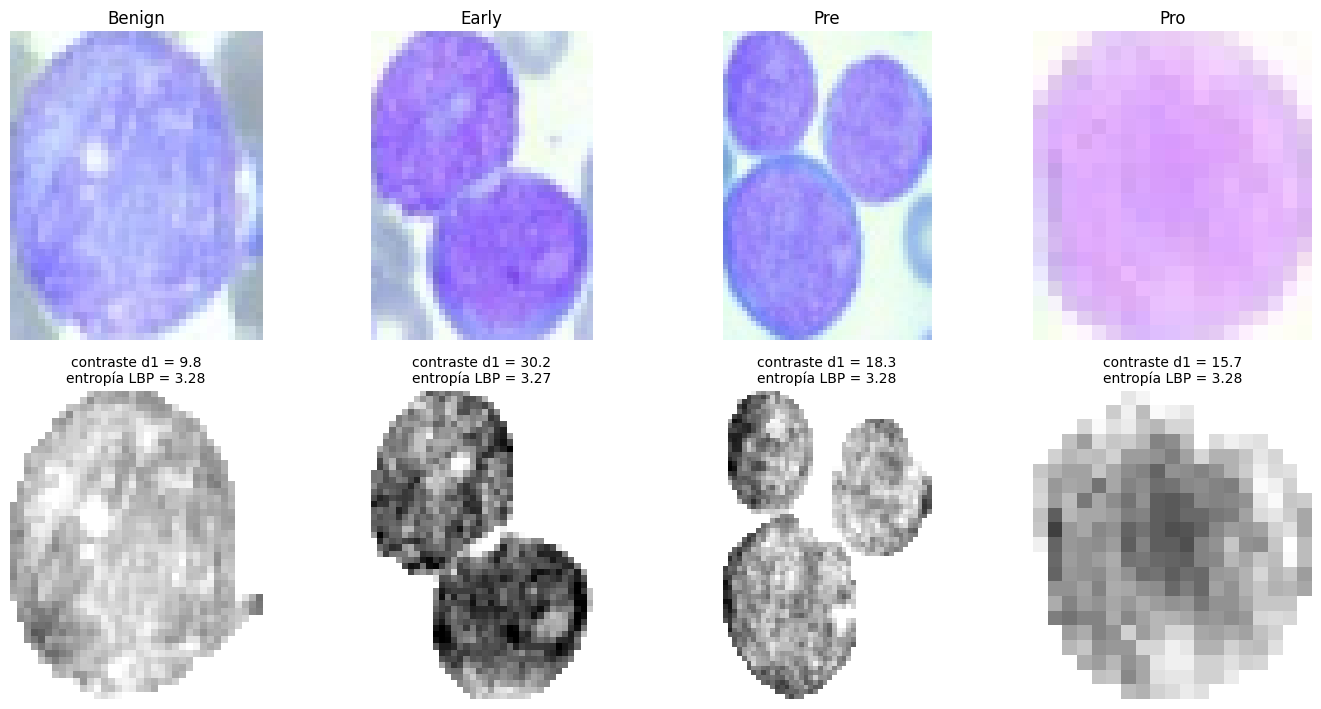

In [17]:
fig, ax = plt.subplots(2, len(subtipos), figsize=(3.6 * len(subtipos), 7.2))
for j, st in enumerate(subtipos):
    r = org[org.subtipo == st].sample(1, random_state=2).iloc[0]
    rgb = preprocesar(leer(r.ruta))
    nucleos, _ = segmentar_componentes(rgb)
    if nucleos.max() == 0:
        continue
    gn = gris_normalizado(rgb, nucleos > 0)
    reg = max(measure.regionprops(segmentation.clear_border(nucleos) if segmentation.clear_border(nucleos).max() else nucleos), key=lambda p: p.area)
    r0, c0, r1, c1 = reg.bbox
    t = descriptores_textura(rgb, nucleos)
    ax[0, j].imshow(rgb[r0:r1, c0:c1]); ax[0, j].set_title(st)
    ax[1, j].imshow(np.where(reg.image, gn[r0:r1, c0:c1], np.nan), cmap='gray', vmin=0, vmax=1)
    ax[1, j].set_title(f"contraste d1 = {t['glcm_contraste_d1']:.1f}\nentropía LBP = {t['lbp_entropia']:.2f}", fontsize=10)
for a in ax.ravel(): a.axis('off')
plt.tight_layout()

### 5.2 Cálculo sobre todo el dataset

In [18]:
filas = []
for r in org.itertuples():
    rgb = preprocesar(leer(r.ruta))
    nucleos, _ = segmentar_componentes(rgb)
    filas.append(dict(archivo=r.archivo, subtipo=r.subtipo, **descriptores_textura(rgb, nucleos)))
textura = pd.DataFrame(filas)
desc = desc.drop(columns=[c for c in TEXTURA if c in desc]).merge(textura, on=['archivo', 'subtipo'])
desc.groupby('subtipo')[TEXTURA].median().round(3).T

subtipo,Benign,Early,Pre,Pro
glcm_contraste_d1,18.545,17.961,15.379,13.312
glcm_homogeneidad_d1,0.317,0.289,0.295,0.332
glcm_energia_d1,0.107,0.084,0.088,0.097
glcm_correlacion_d1,0.531,0.646,0.639,0.710
glcm_contraste_d3,32.499,32.070,27.452,25.880
glcm_homogeneidad_d3,0.242,0.214,0.222,0.236
glcm_energia_d3,0.101,0.078,0.083,0.089
glcm_correlacion_d3,0.184,0.335,0.322,0.411
lbp_entropia,3.261,3.263,3.265,3.254
lbp_plano,0.119,0.117,0.121,0.117


### 5.3 Comparación entre clases

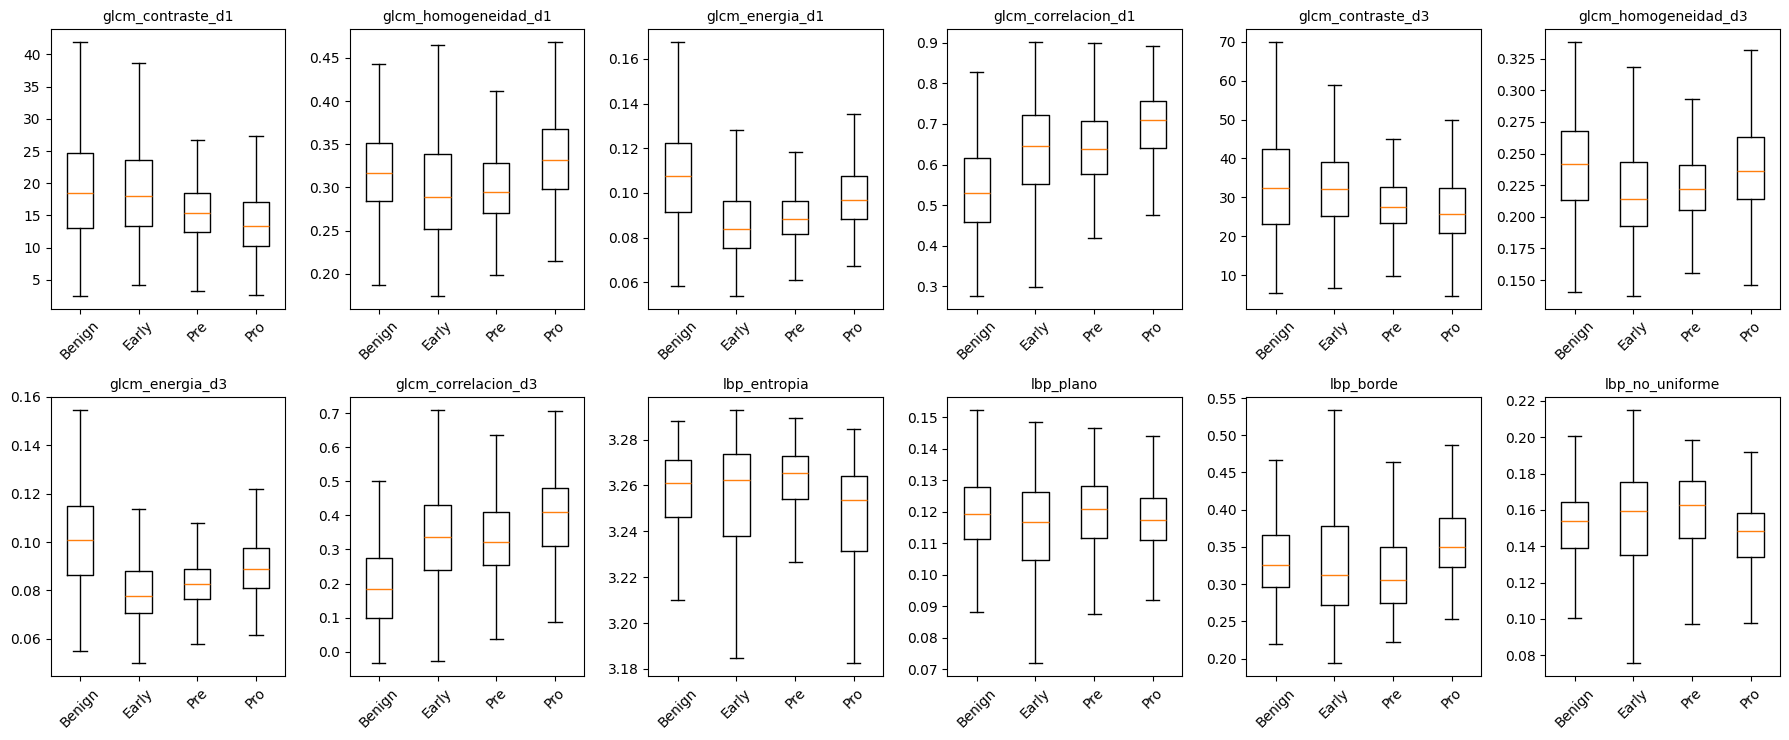

In [19]:
fig, ax = plt.subplots(2, 6, figsize=(18, 7.5))
for a, var in zip(ax.ravel(), TEXTURA):
    a.boxplot([desc.loc[desc.subtipo == st, var].dropna() for st in subtipos], showfliers=False)
    a.set_xticks(range(1, len(subtipos) + 1), subtipos, rotation=45)
    a.set_title(var, fontsize=10)
plt.tight_layout()

In [20]:
desc.groupby('clase')[TEXTURA].median().round(3).T

clase,no patológica,patológica
glcm_contraste_d1,18.545,15.448
glcm_homogeneidad_d1,0.317,0.304
glcm_energia_d1,0.107,0.090
glcm_correlacion_d1,0.531,0.664
glcm_contraste_d3,32.499,28.548
glcm_homogeneidad_d3,0.242,0.224
glcm_energia_d3,0.101,0.083
glcm_correlacion_d3,0.184,0.350
lbp_entropia,3.261,3.261
lbp_plano,0.119,0.118


### 5.4 Observaciones
- **GLCM muestra diferencias descriptivas entre las clases.** En las benignas los núcleos tienen **más contraste** (d = 1: ≈ 18,5 vs. ≈ 15,4) y, sobre todo, **mucha menos correlación** entre vecinos (d = 3: ≈ 0,18 vs. ≈ 0,35, casi la mitad). Estas diferencias podrían estar relacionadas con la distribución de la cromatina: en los linfocitos maduros el gris cambiaría de forma abrupta entre píxeles cercanos (**cromatina en grumos**), y en los linfoblastos de forma gradual (**cromatina fina y homogénea**). Su capacidad discriminativa se evalúa formalmente en el Módulo 4 (Mann-Whitney y curvas ROC).
- La diferencia es más marcada a **d = 3** que a d = 1: los grumos de cromatina ocupan unos pocos píxeles, así que se notan mejor comparando píxeles algo más separados.
- **LBP prácticamente no distingue** (entropía ≈ 3,26 en todas las clases; las fracciones plano/borde/no uniforme difieren en menos de 0,01). Con R = 1 px el LBP mira un vecindario muy chico para imágenes de 224 × 224, donde un núcleo mide ~20 px de diámetro: el patrón a esa escala está dominado por ruido y artefactos JPEG más que por la cromatina. Probar radios mayores (R = 2–3) queda como mejora.
- **Ojo con Pro-B:** tiene el menor contraste y la mayor correlación de todos. Puede ser biológico, pero también puede deberse a que esas imágenes se ven más borrosas o con menos detalle (la normalización compensa la intensidad de la tinción, no el enfoque). Conviene tenerlo en cuenta al interpretar el Módulo 4.
- **Candidatos para el Módulo 4:** `glcm_correlacion_d3`, `glcm_correlacion_d1`, `glcm_contraste_d1`, `glcm_contraste_d3`, `glcm_energia_d1`.

## 6. Compresión y descompresión JPEG
En telepatología o en un sistema de tamizaje las imágenes se almacenan y transmiten **comprimidas**. JPEG es una compresión **con pérdida**: divide la imagen en bloques de 8×8, aplica la **DCT** (transformada discreta del coseno) y **cuantiza** los coeficientes de alta frecuencia más fuertemente cuanto menor es la calidad elegida; al descomprimir, ese detalle fino no se recupera y aparecen artefactos de bloque.

Como nuestros descriptores de textura miden justamente detalle fino, la pregunta es: **¿hasta qué calidad JPEG se puede comprimir sin cambiar la segmentación ni los descriptores?**

**Experimento.** Sobre una muestra estratificada (25 imágenes por subtipo), cada imagen se recomprime en JPEG con calidad 95, 75, 50, 25 y 10, se descomprime y se pasa por el **pipeline completo** (preprocesamiento → segmentación → descriptores). Se mide:
- **tasa de compresión**: tamaño de la imagen sin comprimir (RGB, 3 bytes/píxel) / tamaño del JPEG;
- **PSNR** (dB) y **SSIM** entre la imagen original y la descomprimida (fidelidad de la imagen);
- **Dice** entre la máscara de núcleos original y la obtenida con la imagen comprimida;
- **cambio relativo (%)** de algunos descriptores clave.

*Nota:* las imágenes del dataset ya vienen en JPG, así que es una **recompresión** sobre las originales; también se reporta la tasa de los archivos originales.

Como la semilla de *k*-means está fija (sección 2.1), las diferencias entre la imagen original y la comprimida se deben sólo a la compresión y no a la inicialización aleatoria del agrupamiento.

In [21]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

CALIDADES = [95, 75, 50, 25, 10]
CLAVE = ['area', 'circularidad', 'S_desvio', 'S_rel', 'glcm_contraste_d1', 'glcm_homogeneidad_d1', 'lbp_entropia']

def pipeline(rgb_crudo):
    # Imagen RGB tal como se leyó -> (máscara de núcleos, dict con todos los descriptores).
    rgb = preprocesar(rgb_crudo)
    nucleos, tenido = segmentar_componentes(rgb)
    d = {**descriptores_forma(nucleos), **descriptores_color(rgb, nucleos, tenido), **descriptores_textura(rgb, nucleos)}
    return nucleos > 0, d

def comprimir(rgb, calidad):
    ok, buf = cv2.imencode('.jpg', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, calidad])
    return cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB), len(buf)

muestra_c = org.groupby('subtipo').sample(25, random_state=0)
filas = []
for r in muestra_c.itertuples():
    orig = leer(r.ruta)
    m0, d0 = pipeline(orig)
    filas.append(dict(subtipo=r.subtipo, calidad='original', tasa=orig.nbytes / os.path.getsize(r.ruta)))
    for q in CALIDADES:
        comp, n_bytes = comprimir(orig, q)
        mq, dq = pipeline(comp)
        fila = dict(subtipo=r.subtipo, calidad=q, tasa=orig.nbytes / n_bytes,
                    psnr=peak_signal_noise_ratio(orig, comp),
                    ssim=structural_similarity(orig, comp, channel_axis=2),
                    dice_nucleo=dice(m0, mq))
        for k in CLAVE:
            fila[f'cambio_{k}'] = 100 * abs(dq[k] - d0[k]) / (abs(d0[k]) + 1e-9)
        filas.append(fila)
compresion = pd.DataFrame(filas)
compresion.groupby('calidad', sort=False)[['tasa', 'psnr', 'ssim', 'dice_nucleo']].mean().round(3)

,tasa,psnr,ssim,dice_nucleo
calidad,,,,
original,6.774,NaN,NaN,NaN
95,6.907,43.403,0.983,0.976
75,16.757,34.174,0.900,0.951
50,23.992,32.318,0.871,0.936
25,34.639,30.306,0.833,0.923
10,54.882,27.206,0.759,0.866


,cambio_area,cambio_circularidad,cambio_S_desvio,cambio_S_rel,cambio_glcm_contraste_d1,cambio_glcm_homogeneidad_d1,cambio_lbp_entropia
calidad,,,,,,,
95,1.18,1.41,2.11,0.78,3.83,1.38,0.10
75,3.69,2.55,2.37,3.28,8.90,7.89,0.91
50,4.76,3.31,2.94,4.84,13.24,11.57,2.29
25,6.09,3.87,4.41,7.33,14.51,22.18,4.84
10,11.18,8.06,5.74,12.03,23.75,47.23,11.94


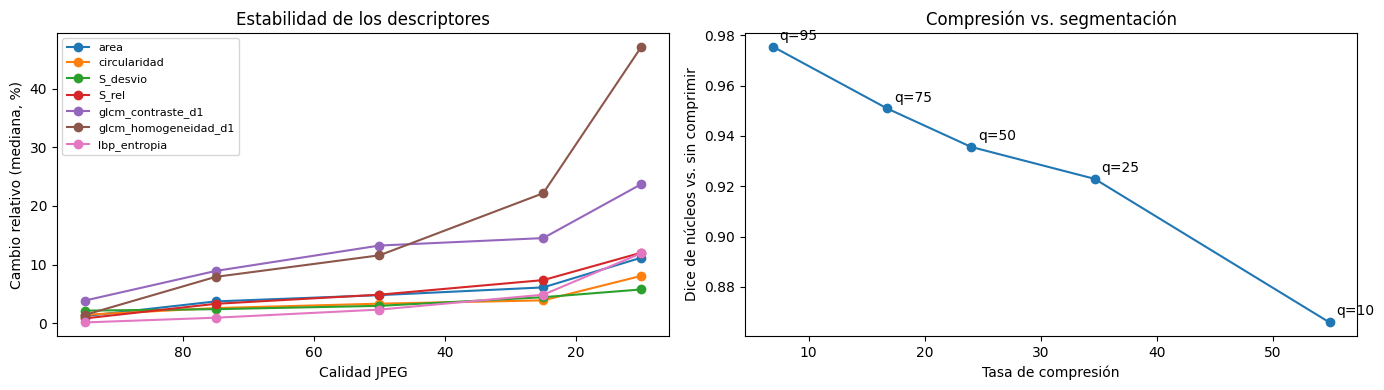

In [22]:
# Cambio relativo de los descriptores clave (mediana, %) según la calidad JPEG
cambios = compresion[compresion.calidad != 'original'].groupby('calidad', sort=False)[[f'cambio_{k}' for k in CLAVE]].median()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k in CLAVE:
    ax[0].plot(CALIDADES, cambios[f'cambio_{k}'], marker='o', label=k)
ax[0].set(xlabel='Calidad JPEG', ylabel='Cambio relativo (mediana, %)', title='Estabilidad de los descriptores')
ax[0].invert_xaxis(); ax[0].legend(fontsize=8)
res = compresion[compresion.calidad != 'original'].groupby('calidad', sort=False)[['tasa', 'dice_nucleo']].mean()
ax[1].plot(res.tasa, res.dice_nucleo, marker='o')
for q, fila in res.iterrows():
    ax[1].annotate(f'q={q}', (fila.tasa, fila.dice_nucleo), textcoords='offset points', xytext=(5, 5))
ax[1].set(xlabel='Tasa de compresión', ylabel='Dice de núcleos vs. sin comprimir', title='Compresión vs. segmentación')
plt.tight_layout()
cambios.round(2)

### 6.1 Observaciones
- **Las imágenes del dataset ya están comprimidas** (tasa ≈ 6,8 : 1 respecto del RGB sin comprimir). Recomprimir con calidad 95 no achica el archivo (≈ 6,9 : 1) y casi no altera la imagen (SSIM 0,98, PSNR 43 dB).
- **El pipeline es sensible incluso a cambios mínimos:** con calidad 95 el Dice de núcleos es 0,976 y el área cambia ~1,2 %. Como la semilla de *k*-means está fija, esta variación no es azar del agrupamiento: pequeñas variaciones de color desplazan unos pocos píxeles el borde de los núcleos. Es un límite inferior del "ruido" de la segmentación.
- **Forma y color resisten bien:** hasta calidad 50 (tasa ≈ 24 : 1, 3,5 veces más chico que el original) los cambios de área, circularidad, desvío de S y S_rel se mantienen por debajo de ~5 %, y el Dice por encima de 0,93.
- **La textura GLCM es lo más afectado**, como era de esperar: JPEG elimina justamente las altas frecuencias (cuantización de los coeficientes DCT), que son el detalle fino que mide la GLCM. La homogeneidad cambia ~8 % con calidad 75, ~12 % con 50 y ~47 % con 10; el contraste, ~9 %, ~13 % y ~24 %.
- **Recomendación:** si el sistema usa descriptores de textura, almacenar y transmitir las imágenes **sin recomprimir** (o con calidad ≥ 95). Si sólo usara forma y color, una calidad de **75** (tasa ≈ 17 : 1, 2,5 veces más chico) sería aceptable (cambios < 4 %, Dice 0,95). Con calidad 10 ninguna parte del análisis es confiable (Dice 0,87, homogeneidad +47 %).

## 7. Control de integridad y exportación
Antes de guardar la tabla se verifica que haya una fila por imagen, sin duplicados, con todos los descriptores y sin valores faltantes o infinitos. Si alguna condición falla, el notebook se detiene y no se guarda una tabla incorrecta.

In [24]:
# Control de integridad de la tabla final

features = FORMA + COLOR + TEXTURA

print("Imágenes procesadas:", len(desc))
print("Descriptores:", len(features))
print("Duplicados:", desc.duplicated(
    subset=['archivo', 'subtipo']
).sum())

print("\nValores faltantes:")
display(desc[features].isna().sum().loc[
    lambda x: x > 0
])

assert len(desc) == len(org)
assert not desc.duplicated(
    subset=['archivo', 'subtipo']
).any()
assert all(c in desc.columns for c in features)
assert np.isfinite(
    desc[features].to_numpy(dtype=float)
).all()

Imágenes procesadas: 3256
Descriptores: 28
Duplicados: 0

Valores faltantes:


,0


In [23]:
desc.to_csv('modulo3_descriptores.csv', index=False)